Iteration  1: Best Position = 1.979731, Best Fitness = 25.979320
Iteration  2: Best Position = 2.600021, Best Fitness = 26.239996
Iteration  3: Best Position = 2.438990, Best Fitness = 26.246278
Iteration  4: Best Position = 2.438990, Best Fitness = 26.246278
Iteration  5: Best Position = 2.438990, Best Fitness = 26.246278
Iteration  6: Best Position = 2.438990, Best Fitness = 26.246278
Iteration  7: Best Position = 2.438990, Best Fitness = 26.246278
Iteration  8: Best Position = 2.438990, Best Fitness = 26.246278
Iteration  9: Best Position = 2.438990, Best Fitness = 26.246278
Iteration 10: Best Position = 2.510162, Best Fitness = 26.249897
Iteration 11: Best Position = 2.510162, Best Fitness = 26.249897
Iteration 12: Best Position = 2.510162, Best Fitness = 26.249897
Iteration 13: Best Position = 2.510162, Best Fitness = 26.249897
Iteration 14: Best Position = 2.510162, Best Fitness = 26.249897
Iteration 15: Best Position = 2.510162, Best Fitness = 26.249897
Iteration 16: Best Positi

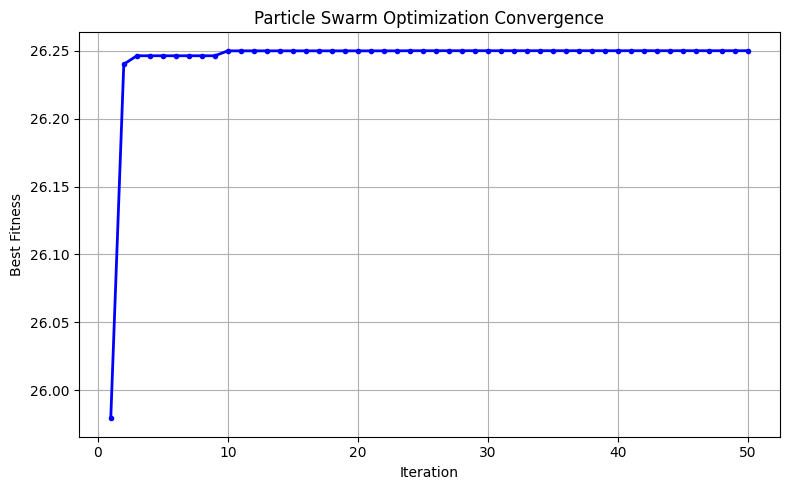

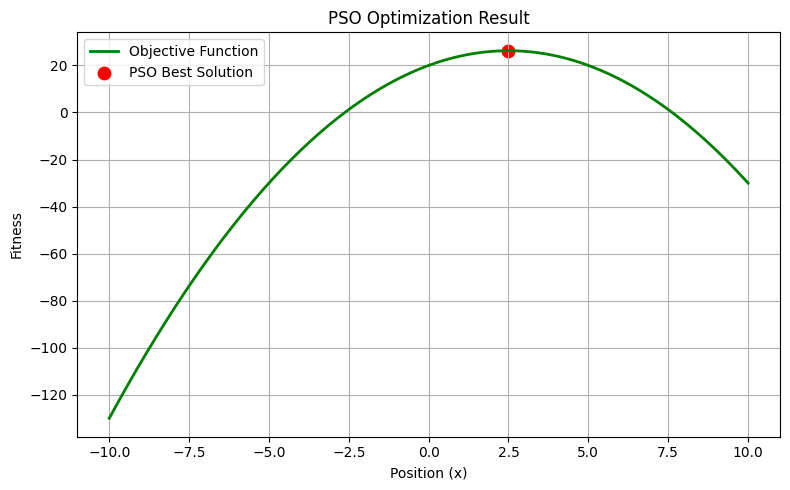

In [1]:

import random
import matplotlib.pyplot as plt

# ============================================================
# PARTICLE SWARM OPTIMIZATION (PSO)
# Maximize f(x) = -x^2 + 5x + 20
# ============================================================

# 1. Objective Function
def objective_function(x):
    return -x**2 + 5*x + 20


# 2. Initialize Parameters
num_particles = 9
max_iterations = 50

w = 0.7
c1 = 1.5
c2 = 1.5

lower_bound = -10
upper_bound = 10


# 3. Initialize Particle Positions
positions = [
    random.uniform(lower_bound, upper_bound)
    for _ in range(num_particles)
]


# 4. Initialize Particle Velocities
velocities = [
    random.uniform(-1, 1)
    for _ in range(num_particles)
]


# 5. Initialize Personal Best (pbest)
pbest_positions = positions.copy()

pbest_values = [
    objective_function(x)
    for x in positions
]


# 6. Initialize Global Best (gbest)
best_index = pbest_values.index(max(pbest_values))

gbest_position = pbest_positions[best_index]
gbest_value = pbest_values[best_index]


# Store convergence history
best_values_history = []


# ============================================================
# 7. PSO MAIN ITERATION
# ============================================================

for iteration in range(max_iterations):

    for i in range(num_particles):

        # Generate random numbers
        r1 = random.random()
        r2 = random.random()

        # Update Velocity
        velocities[i] = (
            w * velocities[i]
            + c1 * r1 *
            (pbest_positions[i] - positions[i])
            + c2 * r2 *
            (gbest_position - positions[i])
        )

        # Update Position
        positions[i] = positions[i] + velocities[i]

        # Apply Boundary Constraints
        positions[i] = max(
            lower_bound,
            min(upper_bound, positions[i])
        )

        # Calculate Fitness
        fitness = objective_function(positions[i])

        # Update Personal Best
        if fitness > pbest_values[i]:

            pbest_positions[i] = positions[i]
            pbest_values[i] = fitness

        # Update Global Best
        if fitness > gbest_value:

            gbest_position = positions[i]
            gbest_value = fitness

    # Store best fitness
    best_values_history.append(gbest_value)

    # Display iteration results
    print(
        f"Iteration {iteration + 1:2d}: "
        f"Best Position = {gbest_position:.6f}, "
        f"Best Fitness = {gbest_value:.6f}"
    )


# ============================================================
# 8. FINAL RESULT
# ============================================================

print("\n====================================")
print("FINAL RESULT")
print("====================================")

print(f"Best Position (x) : {gbest_position:.6f}")
print(f"Best Fitness      : {gbest_value:.6f}")

print("\nTheoretical Solution:")
print("Best Position (x) : 2.5")
print("Maximum Fitness   : 26.25")


# ============================================================
# 9. PLOT CONVERGENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iterations + 1),
    best_values_history,
    color='blue',
    linewidth=2,
    marker='o',
    markersize=3
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("Particle Swarm Optimization Convergence")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. PLOT OBJECTIVE FUNCTION
# ============================================================

x_values = [
    lower_bound + i * (upper_bound - lower_bound) / 200
    for i in range(201)
]

y_values = [
    objective_function(x)
    for x in x_values
]

plt.figure(figsize=(8, 5))

plt.plot(
    x_values,
    y_values,
    color='green',
    linewidth=2,
    label='Objective Function'
)

plt.scatter(
    gbest_position,
    gbest_value,
    color='red',
    s=80,
    label='PSO Best Solution'
)

plt.xlabel("Position (x)")
plt.ylabel("Fitness")
plt.title("PSO Optimization Result")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
